# BO2 · XAI : sur quoi MobileNetV2 s'appuie-t-il pour choisir la classe ? (test d'occlusion)

Le XAI du BO1 (notebook `05_xai_occlusion.ipynb`) demandait si le U-Net **détecte** l'obstacle en regardant l'obstacle. Ici la question est : **pour dire « animal » ou « cône », le classifieur regarde-t-il l'objet, ou le décor autour** (route de campagne, chantier, ville) ? Un modèle qui reconnaît les cônes au décor de chantier se tromperait dès que le décor change.

**Méthode (la même que le BO1).** Sur chaque recadrage 224×224 des régions annotées du test, on cache tour à tour un carré gris de 32×32 (pas de 16) et on mesure la **baisse de probabilité de la classe annoncée**. Une zone rouge est une zone dont dépend la décision.

**Mesure** : part de la sensibilité positive qui tombe sur l'objet, divisée par la part de surface de l'objet dans le recadrage. Un rapport de 1 = le modèle regarde au hasard ; nettement plus que 1 = il s'appuie sur l'objet. On le calcule pour le modèle pré-entraîné **et** le modèle from scratch : le pré-entraînement change-t-il ce que le réseau regarde ?

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

import bo2_mobilenet_commun as C
from bo2_mobilenet_commun import CLASSES, OBJ_CLASSES, DEVICE
torch.set_grad_enabled(False)

OUT_DIR = os.path.join(C.ROOT, "outputs_bo2_mobilenetv2_xai")
os.makedirs(OUT_DIR, exist_ok=True)
PATCH, STRIDE = 32, 16
CASES = ["animals12_Collared_Peccary_crossing_the_road", "cones07", "obstacles11_boulder5", "vehicle02_Broadmoor_Cones_Skidloader"]

df, train_names, val_names, test_names = C.load_split()
CACHE = C.load_cache(df)
CLS_OF = dict(zip(df["name"], df["classe"]))
REG = C.gt_regions(test_names, CACHE)
MODELS = {}
for k, run in [("pré-entraîné", "bo2_mobilenetv2_pretrained"), ("from scratch", "bo2_mobilenetv2_scratch")]:
    m = C.build_mobilenet(pretrained=False)
    m.load_state_dict(torch.load(os.path.join(C.ROOT, "outputs_" + run, run + "_best.pt"), map_location=DEVICE, weights_only=False)["state_dict"])
    MODELS[k] = m.to(DEVICE).eval()
print(len(REG), "régions annotées dans le test | modèles :", list(MODELS))

22 régions annotées dans le test | modèles : ['pré-entraîné', 'from scratch']


## 1. Occlusion sur chaque région du test

In [2]:
def occlusion(model, crop, bs=64):
    x0 = C.to_tensor(crop).unsqueeze(0).to(DEVICE)
    p0 = torch.softmax(model(x0), 1)[0].cpu().numpy(); k = int(p0.argmax())
    S = C.CROP
    boxes = [(y, x) for y in range(0, S - PATCH + 1, STRIDE) for x in range(0, S - PATCH + 1, STRIDE)]
    probs = []
    for i in range(0, len(boxes), bs):
        chunk = boxes[i:i + bs]
        xb = x0.repeat(len(chunk), 1, 1, 1).clone()
        for j, (y, x) in enumerate(chunk):
            xb[j, :, y:y + PATCH, x:x + PATCH] = 0.0           # 0 = gris moyen ImageNet dans l'espace normalisé
        probs.append(torch.softmax(model(xb), 1)[:, k].cpu().numpy())
    probs = np.concatenate(probs)
    sens, cover = np.zeros((S, S)), np.zeros((S, S))
    for (y, x), p in zip(boxes, probs):
        sens[y:y + PATCH, x:x + PATCH] += p0[k] - p; cover[y:y + PATCH, x:x + PATCH] += 1
    return k, float(p0[k]), sens / np.maximum(cover, 1)

def share_inside(sens, mask):
    pos = np.clip(sens, 0, None); tot = pos.sum()
    return float(pos[mask].sum() / tot) if tot > 0 else float("nan")

RES = {k: [] for k in MODELS}
t0 = time.time()
for r in REG:
    img, gt = CACHE[r["name"]]
    box = C.square_box(r["bbox"])
    crop = C.crop_square(img, box)
    mask = C.crop_square(np.repeat((gt > 0).astype(np.uint8)[..., None] * 255, 3, axis=2), box)[..., 0] > 127
    for k, m in MODELS.items():
        cls, conf, sens = occlusion(m, crop)
        RES[k].append({**r, "crop": crop, "mask": mask, "classe": cls, "conf": conf, "sens": sens,
                       "part": share_inside(sens, mask), "surface": float(mask.mean())})
print(f"Occlusion de {len(REG)} régions × {len(MODELS)} modèles en {time.time() - t0:.0f} s")

Occlusion de 22 régions × 2 modèles en 133 s


## 2. Mesure par image (moyenne des régions pondérée par leur surface)

In [3]:
rows = []
for n in test_names:
    row = {"image": n, "vraie classe": CLASSES[CLS_OF[n]]}
    for k in MODELS:
        regs = [q for q in RES[k] if q["name"] == n]
        w = np.array([q["area"] for q in regs], float); w /= w.sum()
        parts = np.array([q["part"] for q in regs]); surfs = np.array([q["surface"] for q in regs]); ok = ~np.isnan(parts)
        vote = np.zeros(4)
        for q, wi in zip(regs, w):
            vote[q["classe"]] += wi
        part = float((parts[ok] * w[ok]).sum() / max(w[ok].sum(), 1e-9)); surf = float((surfs * w).sum())
        row.update({f"{k} : classe": OBJ_CLASSES[int(vote.argmax())], f"{k} : part sur l'objet": part,
                    f"{k} : surface de l'objet": surf, f"{k} : rapport": part / max(surf, 1e-9)})
    rows.append(row)
xai = pd.DataFrame(rows).set_index("image")
display(xai.round(3)); xai.round(4).to_csv(os.path.join(OUT_DIR, "xai_occlusion_tableau.csv"))
for k in MODELS:
    r = xai[k + " : rapport"]
    part_moy = xai[k + " : part sur l'objet"].mean(); surf_moy = xai[k + " : surface de l'objet"].mean()
    print(f"{k:13s} | part moyenne sur l'objet {part_moy:.2f} pour une surface moyenne de {surf_moy:.2f} | rapport médian {r.median():.2f} "
          f"(de {r.min():.2f} à {r.max():.2f}) | images avec rapport < 1,2 : {list(r[r < 1.2].index)}")

,vraie classe,pré-entraîné : classe,pré-entraîné : part sur l'objet,pré-entraîné : surface de l'objet,pré-entraîné : rapport,from scratch : classe,from scratch : part sur l'objet,from scratch : surface de l'objet,from scratch : rapport
image,,,,,,,,,
animals12_Collared_Peccary_crossing_the_road,animal,animal,0.263,0.182,1.446,animal,0.258,0.182,1.421
animals13_jeune_bovin_sur_la_route,animal,animal,0.341,0.190,1.793,animal,0.316,0.190,1.660
animals14_Dekemhare_Road,animal,animal,0.165,0.148,1.120,animal,0.202,0.148,1.370
animals19_Porte_de_Roubaix,animal,animal,0.366,0.198,1.846,cone,0.072,0.198,0.364
animals26_Unnamed_Road_Kazakhstan,animal,animal,0.208,0.170,1.223,animal,0.282,0.170,1.661
animals30,animal,animal,0.519,0.082,6.350,animal,0.071,0.082,0.869
cones04_Federation,cone,cone,0.155,0.109,1.423,cone,0.521,0.109,4.781
cones07,cone,cone,0.339,0.076,4.455,animal,0.042,0.076,0.554
obstacles04_cardboard_czech_hedgehog,obstacle,obstacle,0.468,0.138,3.376,cone,0.347,0.138,2.507


pré-entraîné  | part moyenne sur l'objet 0.33 pour une surface moyenne de 0.15 | rapport médian 1.82 (de 0.66 à 6.35) | images avec rapport < 1,2 : ['animals14_Dekemhare_Road', 'vehicle02_Broadmoor_Cones_Skidloader']
from scratch  | part moyenne sur l'objet 0.24 pour une surface moyenne de 0.15 | rapport médian 1.40 (de 0.36 à 4.78) | images avec rapport < 1,2 : ['animals19_Porte_de_Roubaix', 'animals30', 'cones07']


## 3. Cas d'étude

Pour chaque cas, la plus grande région : recadrage avec le contour de l'objet réel (blanc), puis la sensibilité du modèle pré-entraîné et du modèle from scratch. Rouge = cacher cette zone fait baisser la confiance dans la classe annoncée.

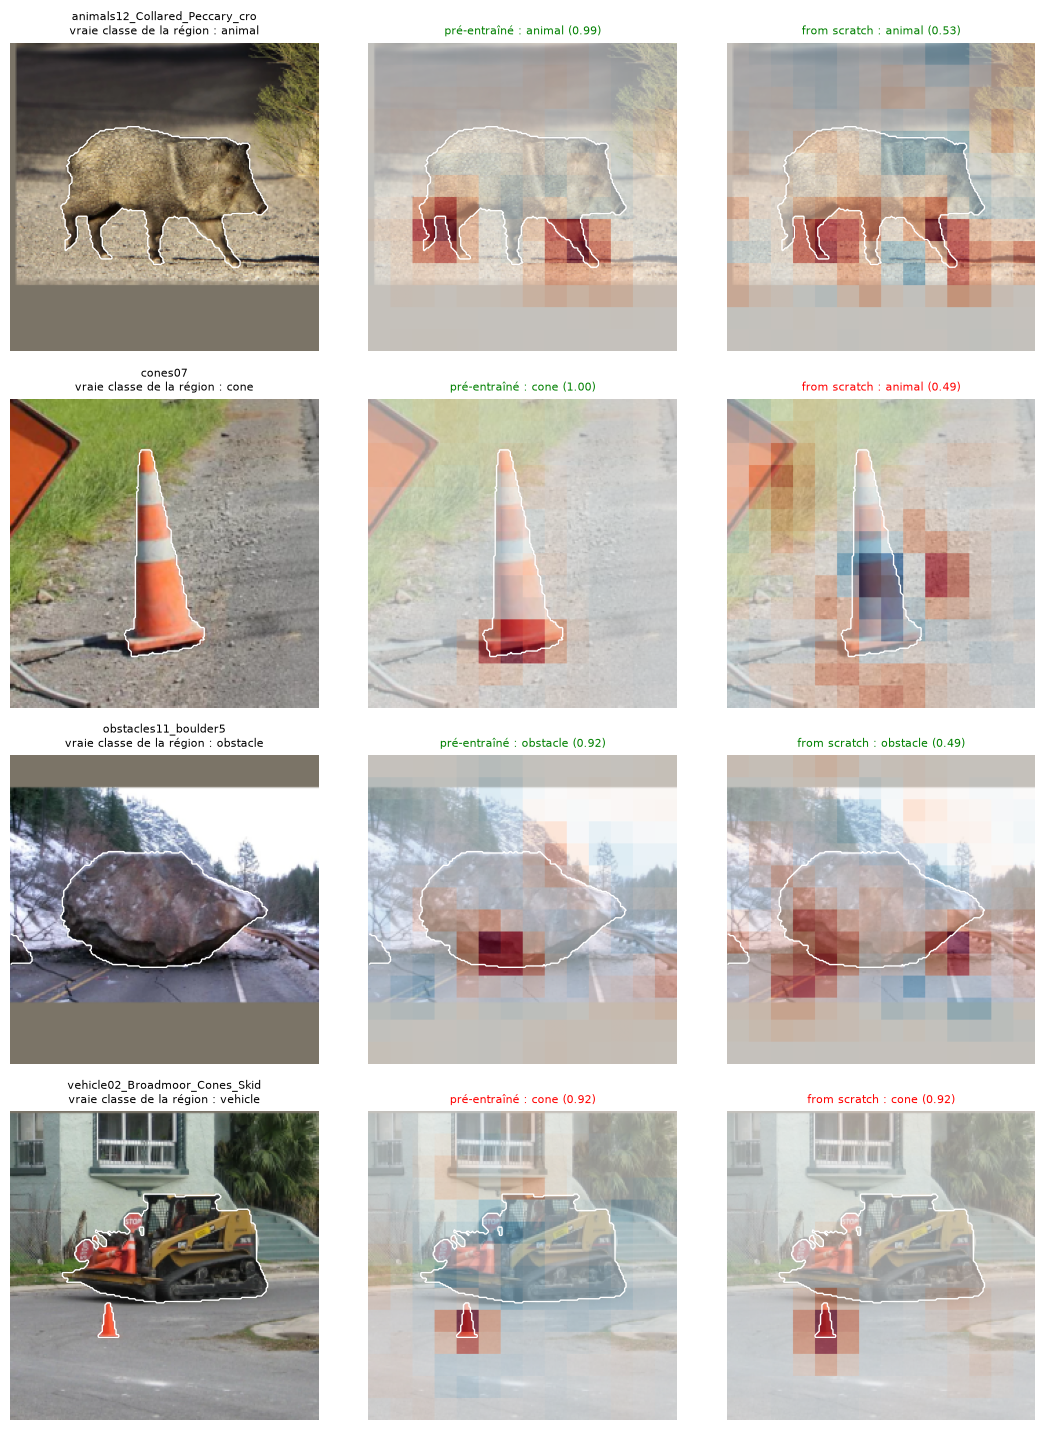

In [4]:
def plot_cases(names, fname):
    fig, axes = plt.subplots(len(names), 3, figsize=(11, 3.6 * len(names)), squeeze=False)
    for i, n in enumerate(names):
        for j, k in enumerate(["pré-entraîné", "from scratch"]):
            q = max([q for q in RES[k] if q["name"] == n], key=lambda q: q["area"])
            if j == 0:
                axes[i, 0].imshow(q["crop"]); axes[i, 0].contour(q["mask"], levels=[0.5], colors="white", linewidths=1)
                axes[i, 0].set_title(f"{n[:30]}\nvraie classe de la région : {OBJ_CLASSES[q['y']]}", fontsize=8)
            v = max(float(np.abs(q["sens"]).max()), 1e-6)
            axes[i, j + 1].imshow(q["crop"]); axes[i, j + 1].imshow(q["sens"], cmap="RdBu_r", vmin=-v, vmax=v, alpha=0.6)
            axes[i, j + 1].contour(q["mask"], levels=[0.5], colors="white", linewidths=1)
            axes[i, j + 1].set_title(f"{k} : {OBJ_CLASSES[q['classe']]} ({q['conf']:.2f})", fontsize=8,
                                     color="green" if q["classe"] == q["y"] else "red")
        for a in axes[i]: a.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, fname), dpi=90, bbox_inches="tight"); plt.show()

plot_cases(CASES, "xai_occlusion_cas_etude.png")

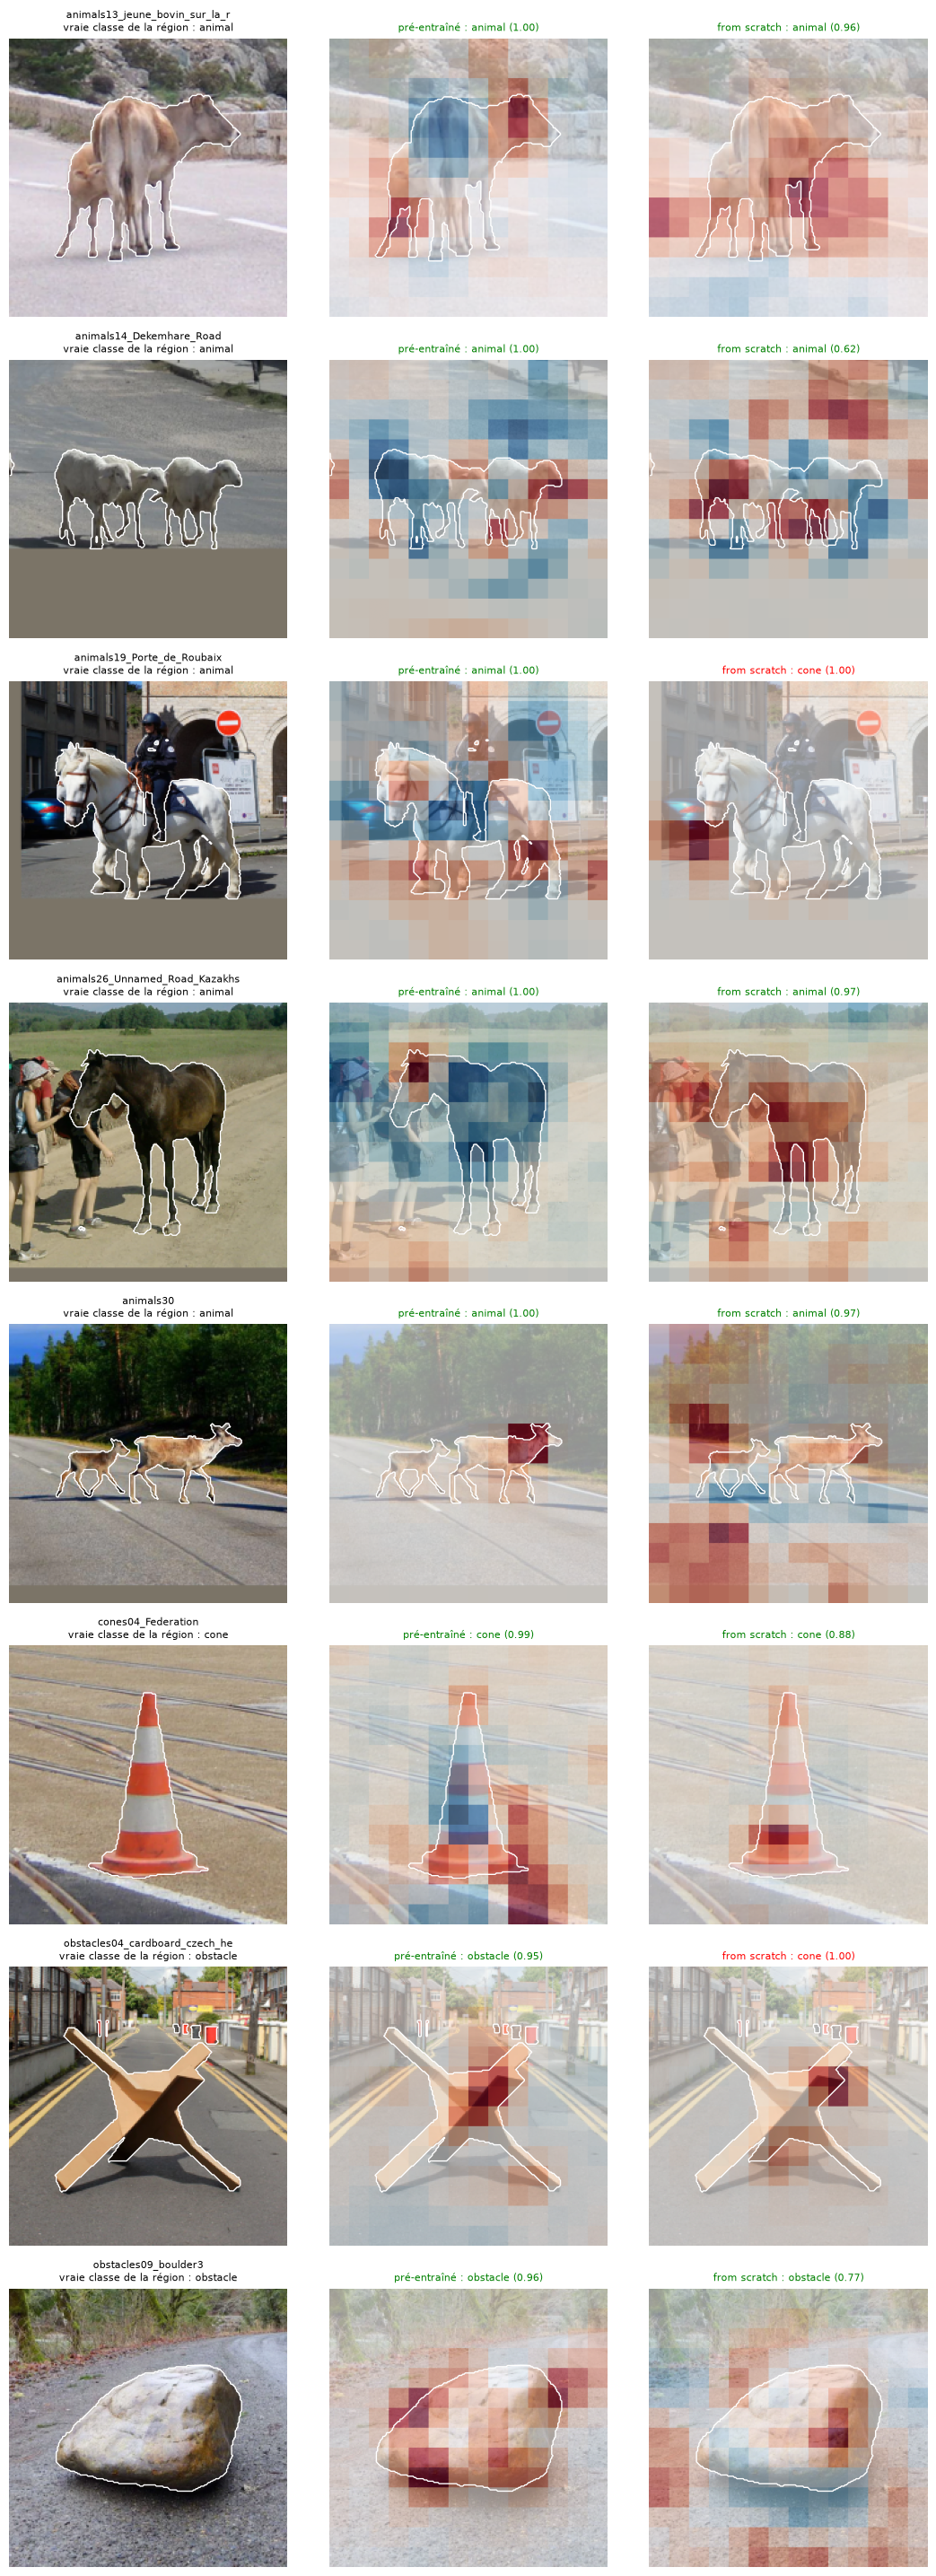

In [5]:
plot_cases([n for n in test_names if n not in CASES], "xai_occlusion_autres_images.png")

**Précautions de lecture** : l'occlusion montre une dépendance, pas une causalité ; le carré gris est lui-même hors distribution ; le recadrage contient 25 % de contexte par construction ; quand la confiance est saturée (proche de 1), les baisses sont faibles et le rapport est bruité ; pour les petits objets, le carré déborde de l'objet ; 12 images ne permettent pas de généraliser.